# Which local shapes repeat in the break case?

**Question:** Can we identify repeated windows without confusing their original positions with a reduced display axis? This lesson follows the structural-break case from its complete observations to a Matrix Profile, a motif pair and candidate segmentation boundaries. The question concerns similarity of local shapes. It does not ask whether an unusual value is dangerous, whether a boundary is a proven change in the generator, or whether an online detector could have issued an alarm at that position.

## Objectives

Keep a window start on the original axis, distinguish shape distance from amplitude and inspect an independently computed profile. Explain why a requested regime count is not a discovered count of true changes.

## Setup

Create an isolated environment and install the exact lesson dependencies below. These package versions identify the numerical environment used for the committed outputs. The lesson reads the small admitted case artifact and performs its own diagnostic calls; it does not download the full benchmark corpus or require a model checkpoint. Keep the source sequence and its observation indices together when comparing the calculated windows with the plotted data.

pip install numpy==2.4.6
pip install scipy==1.15.3
pip install matplotlib==3.10.8
pip install statsforecast==2.0.3
pip install lightgbm==4.6.0
pip install mlforecast==1.0.31
pip install nbformat==5.11.1
pip install nbclient==0.11.0
pip install ipykernel==7.4.0
pip install stumpy==1.14.1
pip install antropy==0.2.2
pip install nolds==0.6.3
pip install pycatch22==0.4.5
pip install scikit-learn==1.9.1


In [1]:
# Configure a portable session and suppress only the known repeated-shape control warning.
from pathlib import Path
import sys
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
root = next(p for p in Path.cwd().parents if (p / "VERSION").is_file())
sys.path.insert(0, str(root / "data-pipeline"))
from chronoscopelab.analysis.sequence import matrix_profile, sequence_report
from chronoscopelab.analysis.sequence import multiscale_entropy, time_reversal
from chronoscopelab.analysis.atlas import prefix_features, associations, by_adjust
plt.rcParams.update({"figure.figsize": (8, 3), "figure.dpi": 95, "font.size": 10})
plt.rcParams["svg.hashsalt"] = "chronoscope-sequence-lessons"
warnings.filterwarnings("ignore", message="A large number of values in.*", category=UserWarning)
import importlib.metadata
packages = ("numpy", "scipy", "matplotlib", "stumpy", "antropy", "nolds", "pycatch22", "scikit-learn",
            "statsforecast", "lightgbm", "mlforecast", "nbformat", "nbclient", "ipykernel")
for package in packages:
    print(package, importlib.metadata.version(package))


numpy 2.4.6
scipy 1.15.3
matplotlib 3.10.8
stumpy 1.14.1
antropy 0.2.2
nolds 0.6.3
pycatch22 0.4.5
scikit-learn 1.9.1
statsforecast 2.0.3
lightgbm 4.6.0
mlforecast 1.0.31
nbformat 5.11.1
nbclient 0.11.0
ipykernel 7.4.0


## Data

The admitted artifact preserves the source identity and the observations used below.


In [2]:
# Read every original observation from the admitted structural-break case.
analysis = json.loads((root / "data/derived/BRKV_level_shift/analysis.json").read_text(encoding="utf-8"))
values = np.array(analysis["sequence"]["values"], dtype=float)
print("Original observations:", len(values))


Original observations: 300


## Method

The case contains three hundred original observations. A window of twenty-four observations moves one position at a time, producing 277 window starts. Every window is centered and divided by its own population standard deviation before distance is measured. Consequently, two windows can have similar normalized shapes even when their absolute levels differ substantially. A change in level is not automatically a shape discord under this definition, and an amplitude threshold would answer a different question.


In [3]:
# Calculate the exact normalized self-join and retain original window positions.
profile = matrix_profile(values, window=24)
print("Window:", profile["window"])
print("Profile starts:", len(profile["profile"]))
print("Motif pairs:", profile["motifs"])
print("Discord windows:", profile["discords"])


Window: 24
Profile starts: 277
Motif pairs: [{'start': 112, 'match': 232, 'distance': 1.9284087073398055}]
Discord windows: [{'start': 187, 'distance': 4.961150848844531}, {'start': 97, 'distance': 4.664855917535791}, {'start': 26, 'distance': 2.690089967466322}]


The self-join excludes nearby trivial matches within a radius of six starts. Without that exclusion, a window could choose itself or a heavily overlapping shifted copy, creating a misleadingly small distance. The motif pair additionally requires non-overlapping windows. Discord candidates are selected by large nearest-neighbor distances, with their query windows separated from one another. Their rank is descriptive: a distance has no calibrated false-alarm probability attached to it.


In [4]:
# Compare the product adapter with the pinned STUMPY reference.
import stumpy
reference = stumpy.stump(values, m=24)
difference = np.max(np.abs(np.asarray(profile["profile"])-reference.P_))
print("Maximum distance from reference:", f"{difference:.8f}")


Maximum distance from reference: 0.00000000


The independent library call exposes the same exact distance profile. Agreement here checks the product adapter's distance extraction on an actual case; the small exhaustive-distance test in the repository supplies a separate numerical oracle. This lesson does not replace that test with an assertion about an attractive picture. Inspect both the distance vector and the integer start positions when considering whether two highlighted windows really refer to the intended observations.


In [5]:
# Run the complete sequence diagnostic with an explicit candidate period.
diagnostics = sequence_report(values, seasonality=12)
print("Original index count:", len(diagnostics["observation_indices"]))
print("FLUSS candidates:", diagnostics["matrix_profile"]["regime_boundaries"])


Original index count: 300
FLUSS candidates: [104, 239]


FLUSS reads nearest-neighbor arcs and constructs a corrected arc curve. The product asks for three candidate regimes and reports their internal boundaries. It is given a count, not the generator's known break locations. This distinction matters: the requested number of regimes must not be presented as an estimate of how many true changes exist. The boundaries use the complete sequence and therefore describe a retrospective analysis rather than information available at an earlier prediction origin.

A second window of twelve observations tests sensitivity to the declared local shape scale. It is a diagnostic comparison, not a search for the most favorable annotation.


In [6]:
# Compare a fixed shorter window without selecting a favorable result.
short_profile = matrix_profile(values, window=12)
print("Short-window motif pair:", short_profile["motifs"])
print("Short-window candidate boundaries:", short_profile["regime_boundaries"])


Short-window motif pair: [{'start': 14, 'match': 134, 'distance': 0.7937109471393579}]
Short-window candidate boundaries: [248, 276]


## Results

**Answer:** The selected motif windows start at 112 and 232 on the original axis. FLUSS proposes boundaries at 104 and 239 for the requested three regimes. These candidates describe the observed shapes; their positions do not establish known generator breaks or a prospective alarm.


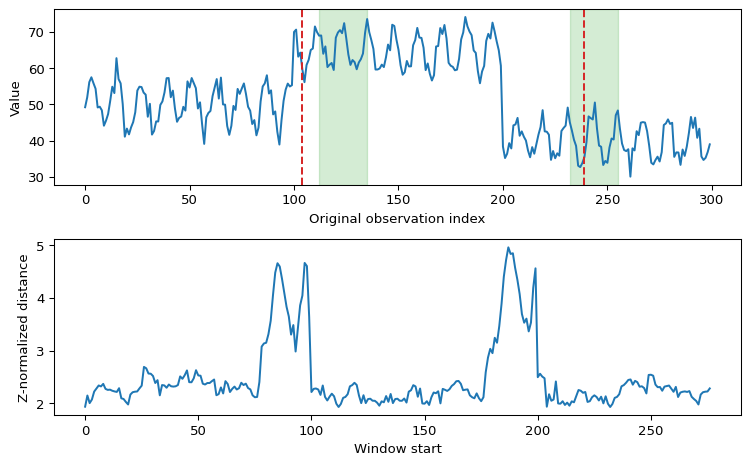

In [7]:
# Connect motif intervals and retrospective boundaries to original observations.
fig, axes = plt.subplots(2, 1, figsize=(8, 5))
axes[0].plot(values, label="original observations")
for boundary in profile["regime_boundaries"]:
    axes[0].axvline(boundary, color="tab:red", linestyle="--")
for motif in profile["motifs"]:
    for start in (motif["start"], motif["match"]):
        axes[0].axvspan(start, start+23, color="tab:green", alpha=.2)
axes[0].set(xlabel="Original observation index", ylabel="Value")
axes[1].plot(profile["profile"], label="nearest-shape distance")
axes[1].set(xlabel="Window start", ylabel="Z-normalized distance")
fig.tight_layout()
plt.show()


The upper panel keeps the original observation axis and shows the motif intervals against the raw values. The lower panel assigns a distance to each window start, so its final index is smaller than the raw sequence's final index. Read the interval width before comparing a profile feature with a point in the upper panel. A minimum identifies a close eligible neighbor; a maximum identifies a window whose best available neighbor is relatively distant under the declared normalization.

Answer: twenty-four-observation windows generate 277 profile positions from 300 original observations. The printed motif and discord records give the candidate locations for this particular run, while the reference-distance difference verifies their numerical source. These observations support a reproducible description of repeated shapes. They do not establish that a particular discord caused a forecast error, nor that FLUSS recovered every level change. A different window length would define different local patterns and requires a separately described comparison.

### Limitations

Normalization removes mean and scale information intentionally. A rare absolute value may therefore have an ordinary shape match, and a common local pattern may occur at an operationally important level. Near-constant windows need the library's stated convention. The complete constant-sequence case is reported as unavailable because it cannot discriminate shapes. The app's original-axis annotations and window tables retain these distinctions instead of resampling positions into an apparently more precise boundary.

## Summary

A window is an interval with a declared normalization and exclusion policy. Original positions, reference distances and retrospective boundaries together make the pattern claim inspectable.

### Reproduce

Run the notebook from top to bottom in the pinned environment. Compare the printed start positions with the admitted sequence artifact and inspect the repository's exhaustive profile and planted-transition tests. Do not substitute a decimated trace for the original observations: that would change both the local shapes and the units of a window length.

## References

Yeh et al., Matrix Profile I, DOI 10.1109/ICDM.2016.0179. Gharghabi et al., Matrix Profile VIII, DOI 10.1109/ICDM.2017.21. The STUMPY exact self-join and FLUSS tutorials document normalization, exclusion and candidate segmentation behavior.
